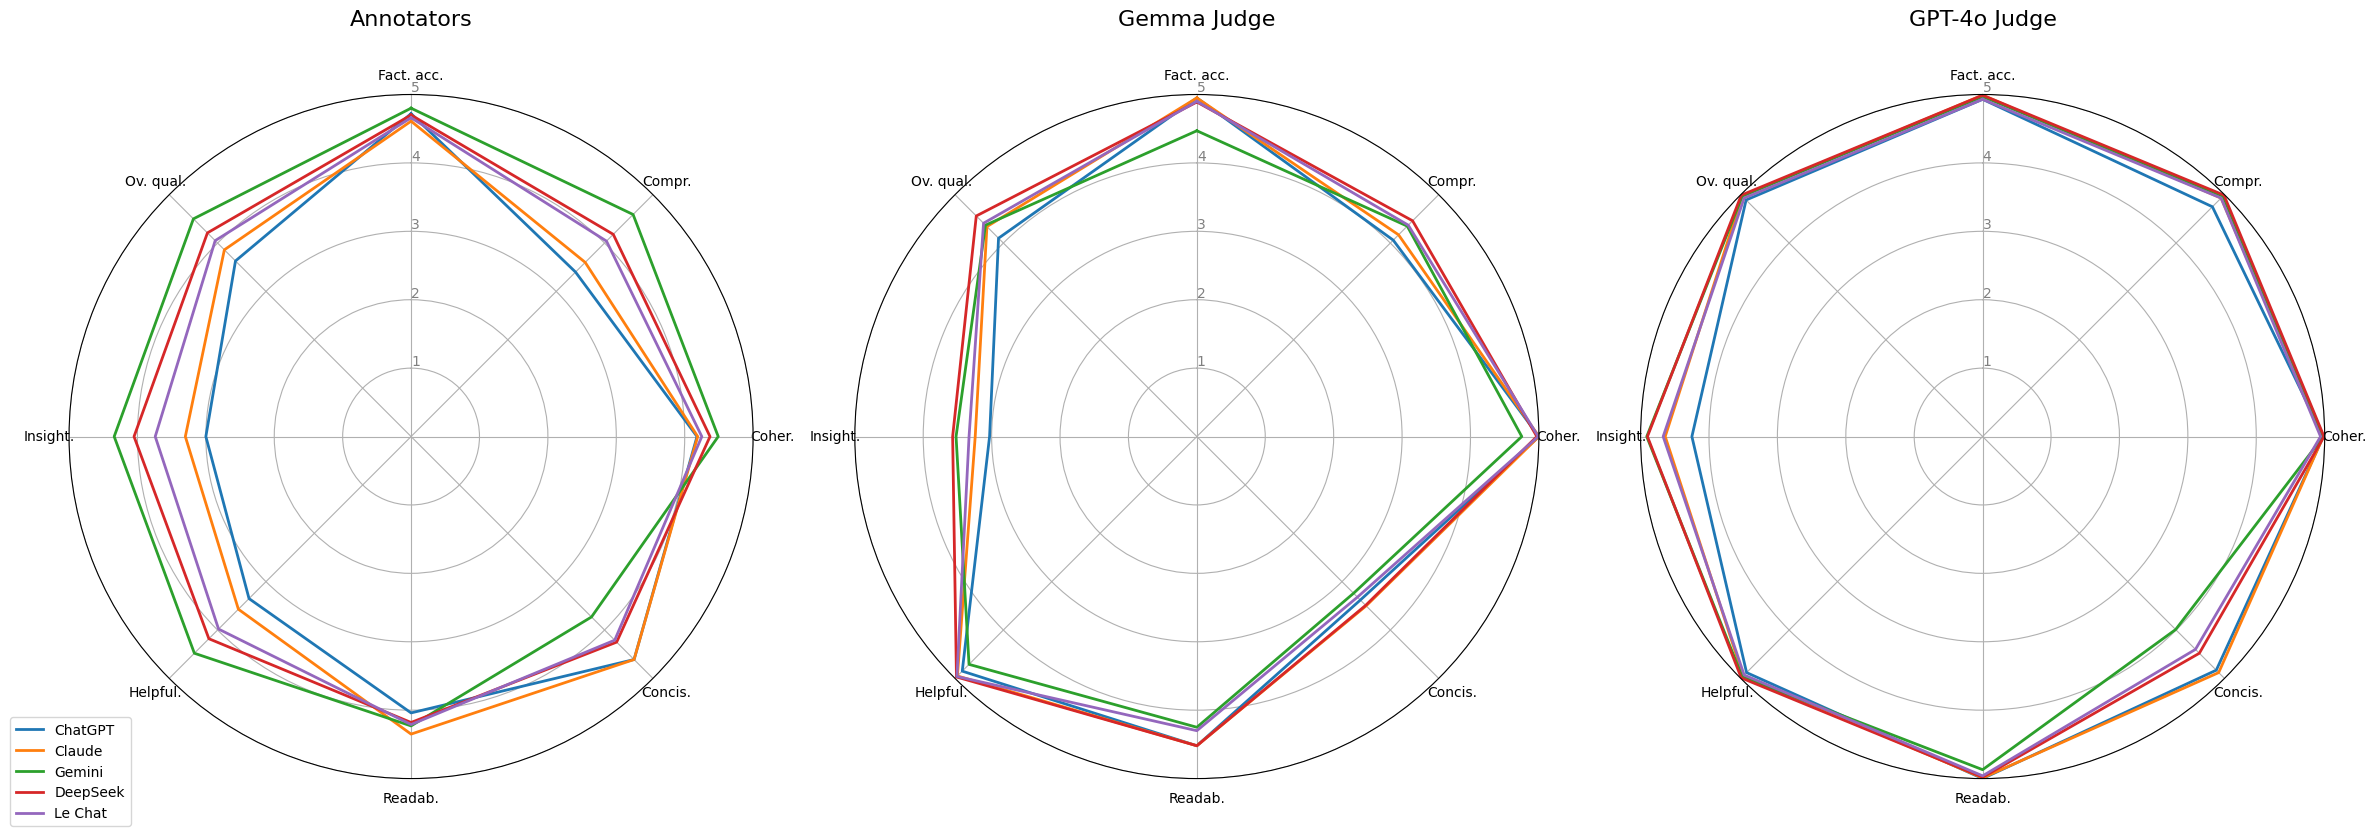

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data from the provided image tables.
data_gemma = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.95, 4.95, 4.47, 4.89, 4.90],
    'Compr.': [4.06, 4.17, 4.35, 4.46, 4.37],
    'Coher.': [5.00, 5.00, 4.75, 4.97, 4.99],
    'Concis.': [3.38, 3.50, 3.24, 3.49, 3.32],
    'Readab.': [4.52, 4.52, 4.25, 4.52, 4.30],
    'Helpful.': [4.85, 4.95, 4.71, 4.97, 4.96],
    'Insight.': [3.03, 3.24, 3.52, 3.57, 3.33],
    'Ov. qual.': [4.10, 4.34, 4.37, 4.56, 4.41]
}

data_gpt4o = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.93, 4.99, 4.97, 4.99, 4.93],
    'Compr.': [4.75, 4.93, 4.97, 4.99, 4.93],
    'Coher.': [4.98, 4.98, 4.98, 4.99, 4.94],
    'Concis.': [4.83, 4.88, 3.99, 4.48, 4.40],
    'Readab.': [5.00, 4.99, 4.87, 4.98, 4.96],
    'Helpful.': [4.88, 4.95, 4.97, 4.99, 4.93],
    'Insight.': [4.25, 4.64, 4.91, 4.90, 4.67],
    'Ov. qual.': [4.89, 4.97, 4.97, 4.99, 4.93]
}

data_nojudge = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.72, 4.61, 4.80, 4.70, 4.66],
    'Compr.': [3.40, 3.60, 4.59, 4.18, 4.04],
    'Coher.': [4.18, 4.19, 4.49, 4.37, 4.25],
    'Concis.': [4.61, 4.61, 3.73, 4.25, 4.21],
    'Readab.': [4.04, 4.35, 4.23, 4.18, 4.21],
    'Helpful.': [3.35, 3.57, 4.48, 4.18, 3.98],
    'Insight.': [3.00, 3.30, 4.34, 4.05, 3.74],
    'Ov. qual.': [3.63, 3.86, 4.50, 4.21, 4.05]
}

df_gemma = pd.DataFrame(data_gemma).set_index('Chatbot')
df_gpt4o = pd.DataFrame(data_gpt4o).set_index('Chatbot')
df_nojudge = pd.DataFrame(data_nojudge).set_index('Chatbot')

# --- Plotting the spider plots in subplots ---

# Number of variables we're plotting.
categories = list(df_gemma.columns)
num_vars = len(categories)

# Calculate angle for each axis in the plot.
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop for plotting.

# Create a figure with three subplots.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 8), subplot_kw=dict(polar=True))
#fig.suptitle('Chatbot Performance on Various Metrics', size=20, y=1.05)

# Plot for No Judge (now first)
ax1.set_title('Annotators', size=16, pad=50)
ax1.set_theta_offset(np.pi / 2)
ax1.set_theta_direction(-1)
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(categories, fontsize=10)
ax1.set_rlabel_position(0)
ax1.set_yticks(np.arange(1, 6, 1))
ax1.set_yticklabels(["1", "2", "3", "4", "5"], color="grey", size=10)
ax1.set_ylim(0, 5)

for i in range(len(df_nojudge)):
    values = df_nojudge.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_nojudge.index[i]
    ax1.plot(angles, values, linewidth=2, linestyle='solid', label=label)

ax1.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))


# Plot for Gemma Judge (now second)
ax2.set_title('Gemma Judge', size=16, pad=50)
ax2.set_theta_offset(np.pi / 2)
ax2.set_theta_direction(-1)
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories, fontsize=10)
ax2.set_rlabel_position(0)
ax2.set_yticks(np.arange(1, 6, 1))
ax2.set_yticklabels(["1", "2", "3", "4", "5"], color="grey", size=10)
ax2.set_ylim(0, 5)

for i in range(len(df_gemma)):
    values = df_gemma.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_gemma.index[i]
    ax2.plot(angles, values, linewidth=2, linestyle='solid', label=label)

#ax2.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

# Plot for GPT-4o Judge (now third)
ax3.set_title('GPT-4o Judge', size=16, pad=50)
ax3.set_theta_offset(np.pi / 2)
ax3.set_theta_direction(-1)
ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(categories, fontsize=10)
ax3.set_rlabel_position(0)
ax3.set_yticks(np.arange(1, 6, 1))
ax3.set_yticklabels(["1", "2", "3", "4", "5"], color="grey", size=10)
ax3.set_ylim(0, 5)

for i in range(len(df_gpt4o)):
    values = df_gpt4o.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_gpt4o.index[i]
    ax3.plot(angles, values, linewidth=2, linestyle='solid', label=label)

#ax3.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

plt.tight_layout()
plt.show()

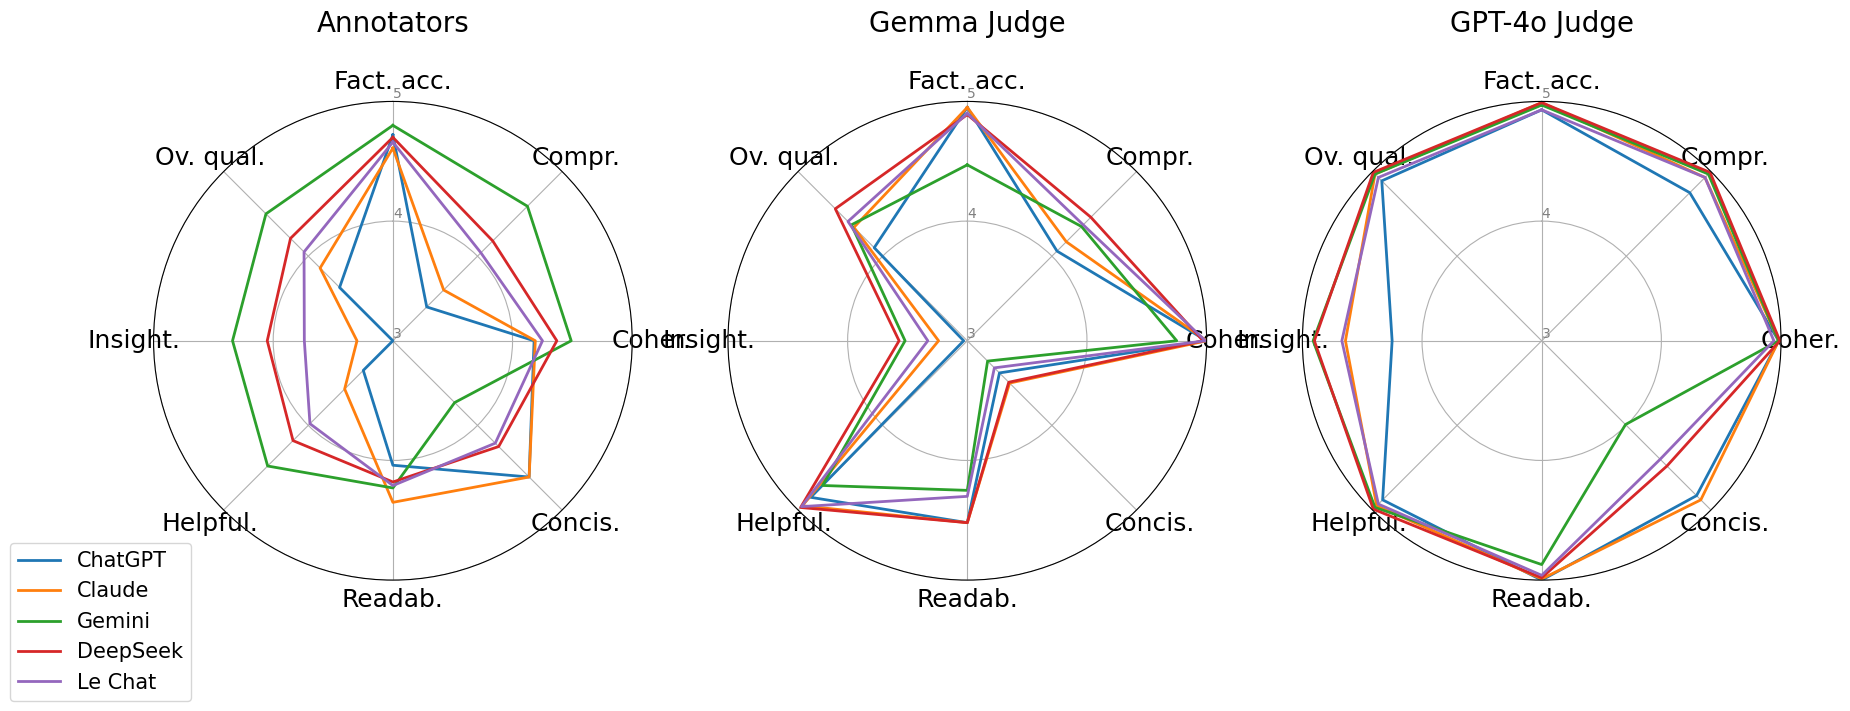

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data from the provided image tables.
data_gemma = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.95, 4.95, 4.47, 4.89, 4.90],
    'Compr.': [4.06, 4.17, 4.35, 4.46, 4.37],
    'Coher.': [5.00, 5.00, 4.75, 4.97, 4.99],
    'Concis.': [3.38, 3.50, 3.24, 3.49, 3.32],
    'Readab.': [4.52, 4.52, 4.25, 4.52, 4.30],
    'Helpful.': [4.85, 4.95, 4.71, 4.97, 4.96],
    'Insight.': [3.03, 3.24, 3.52, 3.57, 3.33],
    'Ov. qual.': [4.10, 4.34, 4.37, 4.56, 4.41]
}

data_gpt4o = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.93, 4.99, 4.97, 4.99, 4.93],
    'Compr.': [4.75, 4.93, 4.97, 4.99, 4.93],
    'Coher.': [4.98, 4.98, 4.98, 4.99, 4.94],
    'Concis.': [4.83, 4.88, 3.99, 4.48, 4.40],
    'Readab.': [5.00, 4.99, 4.87, 4.98, 4.96],
    'Helpful.': [4.88, 4.95, 4.97, 4.99, 4.93],
    'Insight.': [4.25, 4.64, 4.91, 4.90, 4.67],
    'Ov. qual.': [4.89, 4.97, 4.97, 4.99, 4.93]
}

data_nojudge = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.72, 4.61, 4.80, 4.70, 4.66],
    'Compr.': [3.40, 3.60, 4.59, 4.18, 4.04],
    'Coher.': [4.18, 4.19, 4.49, 4.37, 4.25],
    'Concis.': [4.61, 4.61, 3.73, 4.25, 4.21],
    'Readab.': [4.04, 4.35, 4.23, 4.18, 4.21],
    'Helpful.': [3.35, 3.57, 4.48, 4.18, 3.98],
    'Insight.': [3.00, 3.30, 4.34, 4.05, 3.74],
    'Ov. qual.': [3.63, 3.86, 4.50, 4.21, 4.05]
}

df_gemma = pd.DataFrame(data_gemma).set_index('Chatbot')
df_gpt4o = pd.DataFrame(data_gpt4o).set_index('Chatbot')
df_nojudge = pd.DataFrame(data_nojudge).set_index('Chatbot')

# --- Plotting the spider plots in subplots ---

# Number of variables we're plotting.
categories = list(df_gemma.columns)
num_vars = len(categories)

# Calculate angle for each axis in the plot.
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop for plotting.

# Create a figure with three subplots.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), subplot_kw=dict(polar=True))
#fig.suptitle('Chatbot Performance on Various Metrics', size=20, y=1.05)

# Plot for No Judge (now first)
ax1.set_title('Annotators', size=20, pad=50)
ax1.set_theta_offset(np.pi / 2)
ax1.set_theta_direction(-1)
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(categories, fontsize=18)
ax1.set_rlabel_position(0)
ax1.set_yticks(np.arange(3, 6, 1))
ax1.set_yticklabels(["3", "4", "5"], color="grey", size=10)
ax1.set_ylim(3, 5)

for i in range(len(df_nojudge)):
    values = df_nojudge.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_nojudge.index[i]
    ax1.plot(angles, values, linewidth=2, linestyle='solid', label=label)

ax1.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), prop={'size': 15})


# Plot for Gemma Judge (now second)
ax2.set_title('Gemma Judge', size=20, pad=50)
ax2.set_theta_offset(np.pi / 2)
ax2.set_theta_direction(-1)
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories, fontsize=18)
ax2.set_rlabel_position(0)
ax2.set_yticks(np.arange(3, 6, 1))
ax2.set_yticklabels(["3", "4", "5"], color="grey", size=10)
ax2.set_ylim(3, 5)

for i in range(len(df_gemma)):
    values = df_gemma.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_gemma.index[i]
    ax2.plot(angles, values, linewidth=2, linestyle='solid', label=label)

#ax2.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), prop={'size': 8})

# Plot for GPT-4o Judge (now third)
ax3.set_title('GPT-4o Judge', size=20, pad=50)
ax3.set_theta_offset(np.pi / 2)
ax3.set_theta_direction(-1)
ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(categories, fontsize=18)
ax3.set_rlabel_position(0)
ax3.set_yticks(np.arange(3, 6, 1))
ax3.set_yticklabels(["3", "4", "5"], color="grey", size=10)
ax3.set_ylim(3, 5)

for i in range(len(df_gpt4o)):
    values = df_gpt4o.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_gpt4o.index[i]
    ax3.plot(angles, values, linewidth=2, linestyle='solid', label=label)

#ax3.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), prop={'size': 8})

plt.tight_layout()
plt.savefig('spyder.png', transparent=True)
plt.show()

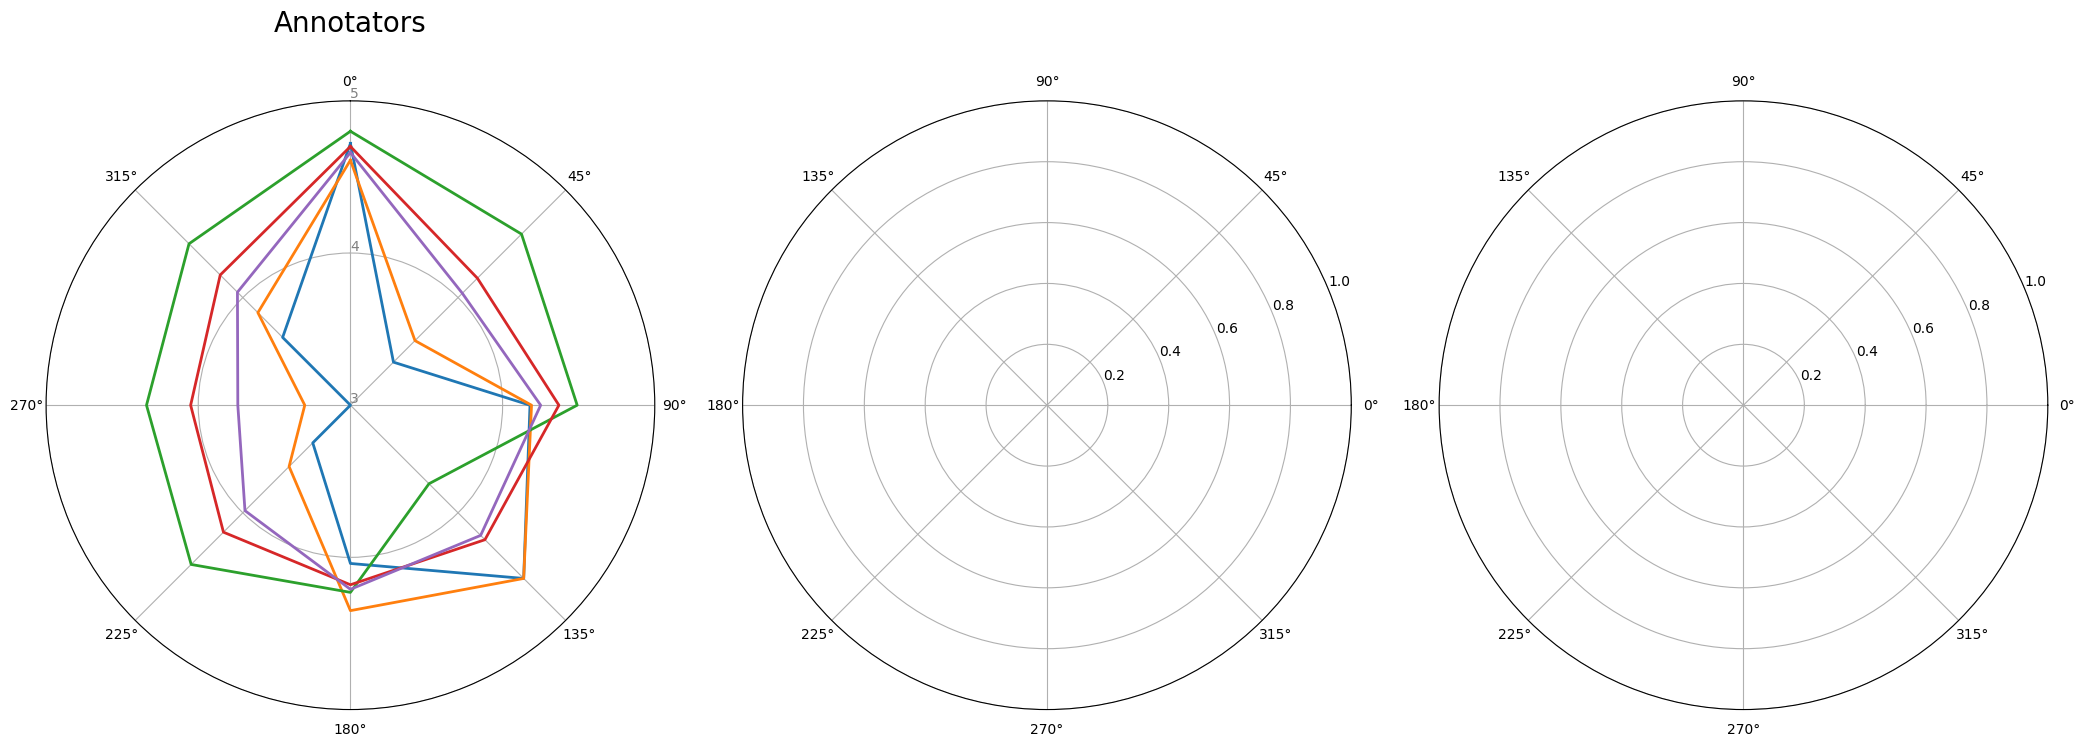

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data from the provided image tables.
data_gemma = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.95, 4.95, 4.47, 4.89, 4.90],
    'Compr.': [4.06, 4.17, 4.35, 4.46, 4.37],
    'Coher.': [5.00, 5.00, 4.75, 4.97, 4.99],
    'Concis.': [3.38, 3.50, 3.24, 3.49, 3.32],
    'Readab.': [4.52, 4.52, 4.25, 4.52, 4.30],
    'Helpful.': [4.85, 4.95, 4.71, 4.97, 4.96],
    'Insight.': [3.03, 3.24, 3.52, 3.57, 3.33],
    'Ov. qual.': [4.10, 4.34, 4.37, 4.56, 4.41]
}

data_gpt4o = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.93, 4.99, 4.97, 4.99, 4.93],
    'Compr.': [4.75, 4.93, 4.97, 4.99, 4.93],
    'Coher.': [4.98, 4.98, 4.98, 4.99, 4.94],
    'Concis.': [4.83, 4.88, 3.99, 4.48, 4.40],
    'Readab.': [5.00, 4.99, 4.87, 4.98, 4.96],
    'Helpful.': [4.88, 4.95, 4.97, 4.99, 4.93],
    'Insight.': [4.25, 4.64, 4.91, 4.90, 4.67],
    'Ov. qual.': [4.89, 4.97, 4.97, 4.99, 4.93]
}

data_nojudge = {
    'Chatbot': ['ChatGPT', 'Claude', 'Gemini', 'DeepSeek', 'Le Chat'],
    'Fact. acc.': [4.72, 4.61, 4.80, 4.70, 4.66],
    'Compr.': [3.40, 3.60, 4.59, 4.18, 4.04],
    'Coher.': [4.18, 4.19, 4.49, 4.37, 4.25],
    'Concis.': [4.61, 4.61, 3.73, 4.25, 4.21],
    'Readab.': [4.04, 4.35, 4.23, 4.18, 4.21],
    'Helpful.': [3.35, 3.57, 4.48, 4.18, 3.98],
    'Insight.': [3.00, 3.30, 4.34, 4.05, 3.74],
    'Ov. qual.': [3.63, 3.86, 4.50, 4.21, 4.05]
}

df_gemma = pd.DataFrame(data_gemma).set_index('Chatbot')
df_gpt4o = pd.DataFrame(data_gpt4o).set_index('Chatbot')
df_nojudge = pd.DataFrame(data_nojudge).set_index('Chatbot')

# --- Plotting the spider plots in subplots ---

# Number of variables we're plotting.
categories = list(df_gemma.columns)
num_vars = len(categories)

# Calculate angle for each axis in the plot.
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop for plotting.

# Create a figure with three subplots.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), subplot_kw=dict(polar=True))
#fig.suptitle('Chatbot Performance on Various Metrics', size=20, y=1.05)

# Plot for No Judge (now first)
ax1.set_title('Annotators', size=20, pad=50)
ax1.set_theta_offset(np.pi / 2)
ax1.set_theta_direction(-1)
ax1.set_xticks(angles[:-1])
#ax1.set_xticklabels(categories, fontsize=18)
ax1.set_rlabel_position(0)
ax1.set_yticks(np.arange(3, 6, 1))
ax1.set_yticklabels(["3", "4", "5"], color="grey", size=10)
ax1.set_ylim(3, 5)

for i in range(len(df_nojudge)):
    values = df_nojudge.iloc[i].values.flatten().tolist()
    values += values[:1]
    label = df_nojudge.index[i]
    ax1.plot(angles, values, linewidth=2, linestyle='solid', label=label)

#ax1.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), prop={'size': 15})



plt.tight_layout()
plt.savefig("test.svg", transparent=True)
plt.show()